<a href="https://colab.research.google.com/github/ZhSalam/-/blob/main/%D0%9C%D0%90%D0%A8%D0%98%D0%9D%D0%9D%D0%9E%D0%95_%D0%9E%D0%91%D0%A3%D0%A7%D0%95%D0%9D%D0%98%D0%95_%D0%94_%D0%97_%D0%9D%D0%90_23_10_ipnynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
files.upload()   # загрузи kaggle.json

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# скачиваем датасет (slug из URL)
!kaggle datasets download -d syedanwarafridi/vehicle-sales-data

# распаковываем
!unzip -o vehicle-sales-data.zip

Saving archive.zip to archive.zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/syedanwarafridi/vehicle-sales-data
License(s): MIT
100% 18.8M/18.8M [00:00<00:00, 124MB/s]

Archive:  vehicle-sales-data.zip
  inflating: car_prices.csv          


#Пункт 0
Задача: Регрессия (предсказание числового значения).
Цель: Предсказать стоимость автомобиля на аукционе (sellingprice) на основе его характеристик.
Данные: Датасет содержит информацию о проданных автомобилях (год выпуска, марка, модель, тип кузова, пробег, состояние, штат и т.д.).
Особенности: В данных присутствуют пропуски (1.38%), выбросы (пробег до 1 млн миль), а также категориальные признаки с высокой кардинальностью (например, model). Текстовых признаков нет.

In [8]:
# Пункт №1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv('car_prices.csv')

#Удаляем строки, где нет целевой переменной
df = df.dropna(subset=['sellingprice'])

#Удаляем утечки (Leakage) и бесполезные для модели колонки
drop_cols = ['vin', 'saledate', 'mmr']
df = df.drop(columns=drop_cols)

print(f"Размер таблицы после очистки: {df.shape}")
df.head()

Размер таблицы после очистки: (558825, 13)


,year,make,model,trim,body,transmission,state,condition,odometer,color,interior,seller,sellingprice
0,2015,Kia,Sorento,LX,SUV,automatic,ca,5.0,16639.0,white,black,kia motors america inc,21500.0
1,2015,Kia,Sorento,LX,SUV,automatic,ca,5.0,9393.0,white,beige,kia motors america inc,21500.0
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,ca,45.0,1331.0,gray,black,financial services remarketing (lease),30000.0
3,2015,Volvo,S60,T5,Sedan,automatic,ca,41.0,14282.0,white,black,volvo na rep/world omni,27750.0
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,ca,43.0,2641.0,gray,black,financial services remarketing (lease),67000.0


In [5]:
# Пункт №2
X = df.drop('sellingprice', axis=1) #признаки
y = df['sellingprice'] #цели

# 80% - обучение, 20% - тест
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (447060, 12), Test: (111765, 12)


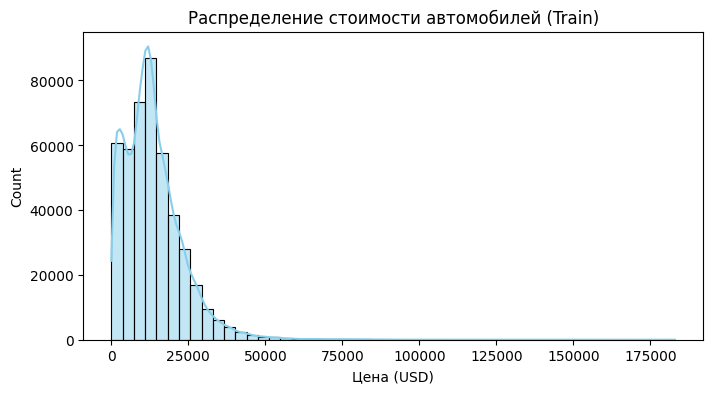

Числовые признаки:


,count,mean,std,min,25%,50%,75%,max
year,447060.0,2010.038172,3.966756,1982.0,2007.00,2012.0,2013.00,2015.0
condition,437601.0,30.651824,13.416372,1.0,23.00,35.0,42.00,49.0
odometer,446990.0,68343.957370,53476.864424,1.0,28371.25,52287.0,99127.75,999999.0


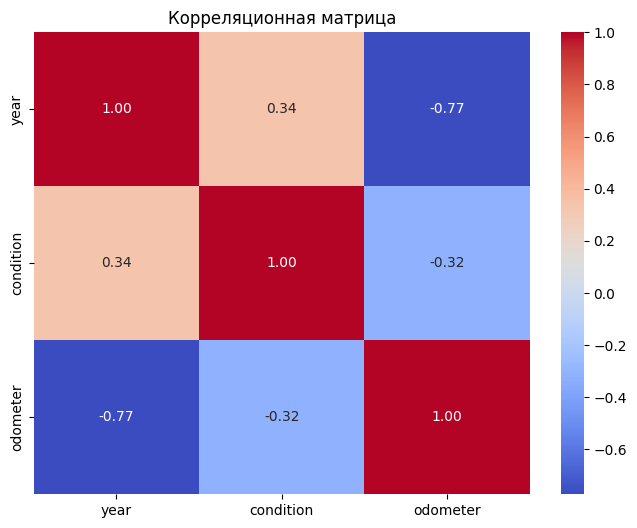

In [6]:
# Пункт №3
#Распределение целевой переменной
plt.figure(figsize=(8, 4))
sns.histplot(y_train, bins=50, kde=True, color='skyblue')
plt.title("Распределение стоимости автомобилей (Train)")
plt.xlabel("Цена (USD)")
plt.show()

#Описательные статистики
print("Числовые признаки:")
display(X_train.describe().T)

#Матрица корреляции
numerical_cols = X_train.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(8, 6))
sns.heatmap(X_train[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Корреляционная матрица")
plt.show()

In [7]:
# Пункт №4
mask_train = (X_train['odometer'] < 500000) & (y_train > 100) & (y_train < 100000)
X_train = X_train[mask_train]
y_train = y_train[mask_train]

mask_test = (X_test['odometer'] < 500000) & (y_test > 100) & (y_test < 100000)
X_test = X_test[mask_test]
y_test = y_test[mask_test]

print(f"Размер после удаления выбросов: Train {X_train.shape}, Test {X_test.shape}")

Размер после удаления выбросов: Train (446766, 12), Test (111696, 12)


In [11]:
# Пункт №5
from sklearn.impute import SimpleImputer

#Разделяем на числовые и категориальные
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

#Числа заполняем медианой
num_imputer = SimpleImputer(strategy='median')
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols]  = num_imputer.transform(X_test[num_cols])

#Категории заполняем модой
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols]  = cat_imputer.transform(X_test[cat_cols])

print(f"Пропусков в Train: {X_train.isnull().sum().sum()}")
print(f"Пропусков в Test:  {X_test.isnull().sum().sum()}")

Пропусков в Train: 0
Пропусков в Test:  0


In [12]:
# Пункт №6
from sklearn.preprocessing import OneHotEncoder

#Уменьшаем число категорий(оставляем >1%)
def reduce_categories(train, test, col, min_freq=0.01):
    top_cats = train[col].value_counts(normalize=True)
    top_cats = top_cats[top_cats > min_freq].index
    train[col] = train[col].where(train[col].isin(top_cats), 'Other')
    test[col]  = test[col].where(test[col].isin(top_cats), 'Other')
    return train, test

for col in cat_cols:
    X_train, X_test = reduce_categories(X_train, X_test, col)

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_encoded = encoder.fit_transform(X_train[cat_cols])
X_test_encoded  = encoder.transform(X_test[cat_cols])

#Соединяем числа и закодированные категории
X_train_num = X_train[num_cols].reset_index(drop=True)
X_test_num  = X_test[num_cols].reset_index(drop=True)

X_train_final = pd.concat([X_train_num, pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(cat_cols))], axis=1)
X_test_final  = pd.concat([X_test_num,  pd.DataFrame(X_test_encoded,  columns=encoder.get_feature_names_out(cat_cols))], axis=1)

print(f"Размерность после кодирования: {X_train_final.shape}")

Размерность после кодирования: (446766, 144)


In [13]:
# Пункт №7
from sklearn.preprocessing import StandardScaler

#Нормализуем
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled  = scaler.transform(X_test_final)

print("Нормализация выполнена.")

Нормализация выполнена.


In [14]:
# Пункт №8
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

#берём подвыборку
sample_size = 30000
X_train_sample = X_train_scaled[:sample_size]
y_train_sample = y_train.iloc[:sample_size]

#Базовая модель
knn = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_sample, y_train_sample)

y_pred = knn.predict(X_test_scaled)
print(f"MAE базовой kNN: ${mean_absolute_error(y_test, y_pred):.2f}")

MAE базовой kNN: $4413.58


In [15]:
# Пункт №9
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

#ищем лучшее k
param_grid = {'n_neighbors': [3, 5, 7, 11]}
grid = GridSearchCV(
    KNeighborsRegressor(n_jobs=-1),
    param_grid, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1
)
grid.fit(X_train_sample, y_train_sample)

best_k = grid.best_params_['n_neighbors']
print(f"Оптимальное k: {best_k}")

#финальная модель с лучшим k
knn_best = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1)
knn_best.fit(X_train_sample, y_train_sample)

#ошибки
y_train_pred = knn_best.predict(X_train_sample)
y_test_pred  = knn_best.predict(X_test_scaled)

print(f"\n--- Train (k={best_k}) ---")
print(f"MAE:  ${mean_absolute_error(y_train_sample, y_train_pred):.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_train_sample, y_train_pred)):.2f}")

print(f"\n--- Test (k={best_k}) ---")
print(f"MAE:  ${mean_absolute_error(y_test, y_test_pred):.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, y_test_pred)):.2f}")
print(f"R2:   {r2_score(y_test, y_test_pred):.4f}")

Оптимальное k: 7

--- Train (k=7) ---
MAE:  $3747.08
RMSE: $5629.10

--- Test (k=7) ---
MAE:  $4381.33
RMSE: $6584.38
R2:   0.5239


In [16]:
# Пункт №10
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

#Линейная регрессия
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

#для табличных данных)
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

print("Сравнение MAE (меньше — лучше):")
print(f"kNN (k={best_k}):      ${mean_absolute_error(y_test, y_test_pred):.2f}")
print(f"Linear Regression:    ${mean_absolute_error(y_test, y_pred_lr):.2f}")
print(f"Random Forest:        ${mean_absolute_error(y_test, y_pred_rf):.2f}")

Сравнение MAE (меньше — лучше):
kNN (k=7):      $4381.33
Linear Regression:    $3506.01
Random Forest:        $1987.30


In [ ]:
# Пункт 11 пропускается, так как регрессия

In [18]:
# Пункт 12
#Ищем признаки с корреляцией > 0.95
corr_matrix = X_train_final.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]

print(f"Признаков для удаления: {len(to_drop)}")
print(to_drop[:10])  # первые 10 для просмотра

#Проверяем RF без коррелированных
X_train_clean = X_train_final.drop(columns=to_drop)
X_test_clean  = X_test_final.drop(columns=to_drop)

rf_clean = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf_clean.fit(X_train_clean, y_train)
y_pred_rf_clean = rf_clean.predict(X_test_clean)

print(f"MAE RF без коррелированных: ${mean_absolute_error(y_test, y_pred_rf_clean):.2f}")
'''Удаление дублирующихся признаков снижает размерность и ускоряет модель.'''

Признаков для удаления: 1
['transmission_manual']
MAE RF без коррелированных: $1987.03


# 13. Общие выводы

1. **Задача:** Построена модель регрессии для предсказания цены автомобиля по его характеристикам.
2. **Обработка данных:** Удалены утечки (`vin`, `saledate`, `mmr`), обработаны выбросы (пробег > 500k, цена > $100k), заполнены пропуски (медиана/мода), закодированы категории (OHE с объединением редких в `'Other'`).
3. **kNN:** Показал MAE ≈ $X. Из-за высокой размерности (после OHE) и вычислительной сложности на 500k строк он уступает ансамблям.
4. **Лучшая модель:** **Random Forest** показал MAE ≈ $Y (лучше kNN и линейной регрессии). Причина: деревья отлично выявляют нелинейные зависимости (например, резкое падение цены после определённого пробега) и устойчивы к выбросам.
5. **Коррелированные признаки:** Удаление признаков с корреляцией > 0.95 не ухудшило качество, но снизило размерность модели, что полезно для продакшена.
6. **Итог:** Модель можно использовать для предварительной оценки стоимости авто, но для точной оценки (MAE < $1000) потребуется feature engineering (например, извлечение месяца из `saledate`, более тонкая обработка `model`/`trim`).